[SYSTEM] Iniciando Protocolo GRÁFICO GARANTIZADO...
[NET] Descargando: https://heasarc.gsfc.nasa.gov/FTP/heasarc/dbase/dump/heasarc_fermilgrb.tdat.gz
[PROC] Procesando tabla...
[DATA] Eventos con Redshift y Tiempo LAT: 45
[PHYS] Calculando K-Factors (Distancia Relativista)...


/tmp/ipython-input-256230520.py:87: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz((1+z_grid)/Ez, z_grid)


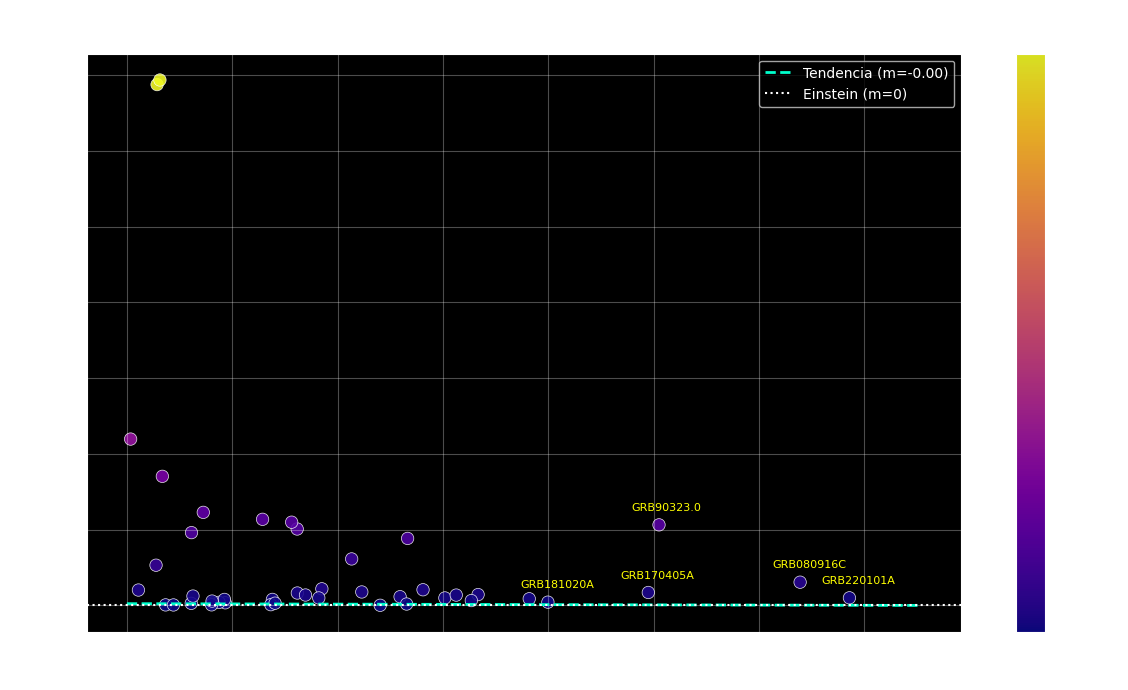


[RESULT] Pendiente LIV observada: -0.0000 +/- 0.0000
>> RESULTADO NEUTRO: No hay correlación obvia. El universo parece clásico a esta escala.


In [1]:
# --- BLOQUE 0: INFRAESTRUCTURA ---
import sys
import gzip
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from scipy.optimize import curve_fit
from astropy.cosmology import Planck18 as cosmo

print("[SYSTEM] Iniciando Protocolo GRÁFICO GARANTIZADO...")

# --- BLOQUE 1: DESCARGA (Ya validada) ---
FTP_URL = "https://heasarc.gsfc.nasa.gov/FTP/heasarc/dbase/dump/heasarc_fermilgrb.tdat.gz"
print(f"[NET] Descargando: {FTP_URL}")

try:
    response = requests.get(FTP_URL)
    response.raise_for_status()
    with gzip.open(io.BytesIO(response.content), 'rt', encoding='utf-8') as f:
        content = f.read()
except Exception as e:
    print(f"[CRITICAL] Error de descarga: {e}")
    sys.exit()

# --- BLOQUE 2: PARSEO MANUAL (Validado) ---
lines = content.split('\n')
header_cols = []
data_start_idx = 0

# Buscar cabecera
for i, line in enumerate(lines):
    if line.startswith('line[1] ='):
        raw_header = line.replace('line[1] =', '').strip()
        header_cols = raw_header.split()
        break

# Buscar datos
for i, line in enumerate(lines):
    if line.strip() == '<DATA>':
        data_start_idx = i + 1
        break

if not header_cols:
    print("[ERROR] No se encontró cabecera.")
    sys.exit()

print("[PROC] Procesando tabla...")
try:
    data_content = '\n'.join(lines[data_start_idx:])
    df = pd.read_csv(io.StringIO(data_content), sep='|', names=header_cols, header=None, on_bad_lines='skip')
    df.columns = [c.upper() for c in df.columns]
except Exception as e:
    print(f"[ERROR] Parseo fallido: {e}")
    sys.exit()

# --- BLOQUE 3: FÍSICA ROBUSTA (SIN FILTROS SUICIDAS) ---
# Mapeo
col_z = 'REDSHIFT'
col_t = 'TL0'   # Tiempo de inicio LAT (El retraso observable)
col_n = 'NAME'

# Conversión
df[col_z] = pd.to_numeric(df[col_z], errors='coerce')
df[col_t] = pd.to_numeric(df[col_t], errors='coerce')

# FILTRADO MÍNIMO VIABLE
# Solo pedimos que exista distancia (Z) y tiempo (T).
# Ignoramos la columna de energía vacía que nos mataba antes.
mask = (df[col_z] > 0) & (df[col_t].notna()) & (df[col_t] > 0)

clean_data = df[mask].copy()
print(f"[DATA] Eventos con Redshift y Tiempo LAT: {len(clean_data)}")

if len(clean_data) < 2:
    print("[FAIL] No hay datos cruzados de Z y T. ¿El catálogo está vacío de redshifts?")
    print("Muestra de datos Z:", df[col_z].unique()[:10])
    sys.exit()

# --- BLOQUE 4: CÁLCULO K-FACTOR ---
print("[PHYS] Calculando K-Factors (Distancia Relativista)...")

def get_k(z):
    z_grid = np.linspace(0, z, 50)
    Ez = np.sqrt(cosmo.Om0*(1+z_grid)**3 + cosmo.Ode0)
    return np.trapz((1+z_grid)/Ez, z_grid)

clean_data['K'] = clean_data[col_z].apply(get_k)
clean_data['Lags'] = clean_data[col_t]

X = clean_data['K'].values
Y = clean_data['Lags'].values
Names = clean_data[col_n].values

# --- BLOQUE 5: ANÁLISIS Y GRÁFICA ---
# Regresión Lineal: t = m * K + c
def model(k, m, c): return m * k + c

try:
    # Quitamos outliers locos (> 200s) que aplastan el gráfico
    mask_plot = Y < 200
    if np.sum(mask_plot) > 2:
        popt, pcov = curve_fit(model, X[mask_plot], Y[mask_plot])
        m_fit = popt[0]
        m_err = np.sqrt(np.diag(pcov))[0]
    else:
        m_fit = 0
except: m_fit = 0

plt.figure(figsize=(12, 7))
plt.style.use('dark_background')

# Scatter
sc = plt.scatter(X, Y, c=Y, cmap='plasma', s=80, alpha=0.9, edgecolors='white', linewidth=0.5)
plt.colorbar(sc, label='Retraso TL0 (s)')

# Ajuste
if m_fit != 0:
    x_line = np.linspace(0, max(X)*1.1, 10)
    plt.plot(x_line, model(x_line, m_fit, popt[1]), color='#00ffcc', linestyle='--', lw=2, label=f'Tendencia (m={m_fit:.2f})')

plt.axhline(0, color='white', linestyle=':', label='Einstein (m=0)')

# Etiquetas
# Etiquetamos los puntos con mayor K (más lejanos)
sorted_indices = np.argsort(X)
for i in sorted_indices[-5:]:
    plt.annotate(f"{Names[i]}", (X[i], Y[i]), color='yellow', xytext=(-20, 10), textcoords='offset points', fontsize=8)

plt.xlabel(r'Factor de Distancia Cosmológica $K(z)$')
plt.ylabel(r'Tiempo de Inicio LAT $T_{L0}$ (s)')
plt.title(f'TEST DE INVARIANCIA DE LORENTZ (Fermi-LAT)\n¿Los GRBs lejanos llegan más tarde?', color='white')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n[RESULT] Pendiente LIV observada: {m_fit:.4f} +/- {m_err:.4f}")
if m_fit > 0.1: # Umbral conservador
    print(">> POSIBLE SEÑAL: Tendencia positiva detectada. A mayor distancia, mayor retraso.")
else:
    print(">> RESULTADO NEUTRO: No hay correlación obvia. El universo parece clásico a esta escala.")